# Testing Honesto del Modelo Azure AutoML

Este notebook evalua el modelo de Azure AutoML **sin overfitting**: usamos un split temporal donde el set de test
son las carreras de la temporada 2026, que el modelo **nunca ha visto** durante su entrenamiento.

### Split Temporal
- **Train**: Temporadas 2022 a 2025 (datos historicos)
- **Test**: Temporada 2026 (datos que el modelo JAMAS ha visto)

> **NOTA**: Para ejecutar este notebook necesitas el entorno `venv_azure` (Python 3.9 + azureml-train-automl-runtime).

In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score
from scipy.stats import spearmanr, kendalltau

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Imports OK")


Imports OK


### 1. Carga del Modelo y Dataset

In [2]:
model_azure = joblib.load("../models/model.pkl")
print("Modelo Azure AutoML cargado:", type(model_azure))

df = pd.read_csv(r"../data/raw/elite_masculina_triatlon/dataset/dataset_automl_entrenamiento.csv")
print(f"Dataset: {len(df)} filas, {df['race_season'].nunique()} temporadas")
print(f"Temporadas: {sorted(df['race_season'].unique())}")

# Columnas a excluir (targets + identificadores)
cols_drop = ["finish_position", "categoria_target", "peso_ejemplo", "inversa_posicion",
             "log_posicion", "race_season", "race_event_desc", "race_phase", "athlete_club"]


Modelo Azure AutoML cargado: <class 'azureml.training.tabular.models.forecasting_pipeline_wrapper.RegressionPipeline'>
Dataset: 1987 filas, 5 temporadas
Temporadas: [2022, 2023, 2024, 2025, 2026]


### 2. Split Temporal
Separamos por temporada: entrenamiento con datos historicos, test con la temporada mas reciente.

In [3]:
test_seasons = [2026]
train_seasons = [2022, 2023, 2024, 2025]

df_train = df[df["race_season"].isin(train_seasons)].copy()
df_test = df[df["race_season"].isin(test_seasons)].copy()

print(f"Train: {len(df_train)} filas (temporadas {train_seasons})")
print(f"Test:  {len(df_test)} filas (temporada {test_seasons}) - NUNCA VISTAS")
print()

# Carreras unicas en test
carreras_test = df_test.groupby(["race_event_desc", "race_season"]).size().sort_values(ascending=False)
print("Carreras en el set de test:")
for (evento, season), n in carreras_test.items():
    print(f"  {evento} ({season}): {n} participantes")


Train: 1568 filas (temporadas [2022, 2023, 2024, 2025])
Test:  419 filas (temporada [2026]) - NUNCA VISTAS

Carreras en el set de test:
  ÉLITE MASCULINA (2026): 132 participantes
  Élite Masculino (2026): 113 participantes
  Élite Masculina (2026): 111 participantes
  Elite Masculina (2026): 63 participantes


### 3. Prediccion en la Carrera de Test con mas Participantes
Seleccionamos la carrera mas grande del set de test para evaluarla en detalle.

In [4]:
# Seleccionar la carrera mas grande del test
evento_test, season_test = carreras_test.index[0]
n_part = carreras_test.iloc[0]
print(f"Carrera seleccionada: {evento_test} ({season_test}) con {n_part} participantes")

df_carrera = df_test[(df_test["race_event_desc"] == evento_test) & (df_test["race_season"] == season_test)].copy()

# Preparar X (quitar targets e identificadores)
X_carrera = df_carrera.drop(columns=[c for c in cols_drop if c in df_carrera.columns])

# Predecir
predicciones = model_azure.predict(X_carrera)

# Construir tabla de resultados
resultados = df_carrera[["finish_position"]].copy()
if "athlete_club" in df_carrera.columns:
    resultados.insert(0, "athlete_club", df_carrera["athlete_club"])
resultados["PREDICCION_MODELO"] = predicciones

# Azure predice finish_position (menor = mejor)
resultados_ordenados = resultados.sort_values(by="PREDICCION_MODELO", ascending=True)
resultados_ordenados["RANKING_PREDICHO"] = range(1, len(resultados_ordenados) + 1)

resultados_finales = resultados_ordenados.sort_values(by="finish_position")
print("\n--- TOP 15 de la carrera (datos NUNCA VISTOS) ---")
display(resultados_finales.head(15))


Carrera seleccionada: ÉLITE MASCULINA (2026) con 132 participantes

--- TOP 15 de la carrera (datos NUNCA VISTOS) ---


,athlete_club,finish_position,PREDICCION_MODELO,RANKING_PREDICHO
1855,CLUB DEPORTIVO DELIKIA,1.00,2.28,1
1856,PEÑOTA DENTAL TRIATLON,2.00,7.48,4
1857,PEÑOTA DENTAL TRIATLON,2.00,7.48,5
1859,PEÑOTA DENTAL TRIATLON,3.00,17.14,19
1858,PEÑOTA DENTAL TRIATLON,3.00,17.14,18
1860,CLUB DEPORTIVO DELIKIA,4.00,5.12,2
1861,CLUB DEPORTIVO DELIKIA,4.00,5.12,3
1862,DEPORAMA TRIATLÓN SORIANO,5.00,8.83,8
1863,DEPORAMA TRIATLÓN SORIANO,6.00,11.52,11
1865,PEÑOTA DENTAL TRIATLON,7.00,8.02,6


### 4. Metricas de la Carrera Individual

In [5]:
mae_pos = mean_absolute_error(resultados_finales["finish_position"], resultados_finales["RANKING_PREDICHO"])
corr_spearman, pval_sp = spearmanr(resultados_finales["finish_position"], resultados_finales["RANKING_PREDICHO"])
corr_kendall, pval_kt = kendalltau(resultados_finales["finish_position"], resultados_finales["RANKING_PREDICHO"])

print("=== METRICAS DE RANKING ===")
print(f"MAE de Posicion:       {mae_pos:.2f} puestos de diferencia de media")
print(f"Correlacion Spearman:  {corr_spearman:.3f} (p-value: {pval_sp:.3e})")
print(f"Correlacion Kendall:   {corr_kendall:.3f} (p-value: {pval_kt:.3e})")
print()

# Precision por Top N
print("=== PRECISION POR TOP N ===")
for n in [3, 5, 10, 15, 20, 50]:
    if n > len(resultados_finales):
        continue
    real_set = set(resultados_finales.head(n).index)
    pred_set = set(resultados_ordenados.head(n).index)
    acc = len(real_set.intersection(pred_set))
    print(f"  Top {n:2d}: {acc}/{n} atletas correctos ({acc/n*100:.0f}%)")


=== METRICAS DE RANKING ===
MAE de Posicion:       31.20 puestos de diferencia de media
Correlacion Spearman:  0.925 (p-value: 1.926e-56)
Correlacion Kendall:   0.759 (p-value: 7.445e-38)

=== PRECISION POR TOP N ===
  Top  3: 1/3 atletas correctos (33%)
  Top  5: 3/5 atletas correctos (60%)
  Top 10: 7/10 atletas correctos (70%)
  Top 15: 11/15 atletas correctos (73%)
  Top 20: 15/20 atletas correctos (75%)
  Top 50: 42/50 atletas correctos (84%)


### 5. Panel de Graficas - Carrera Individual

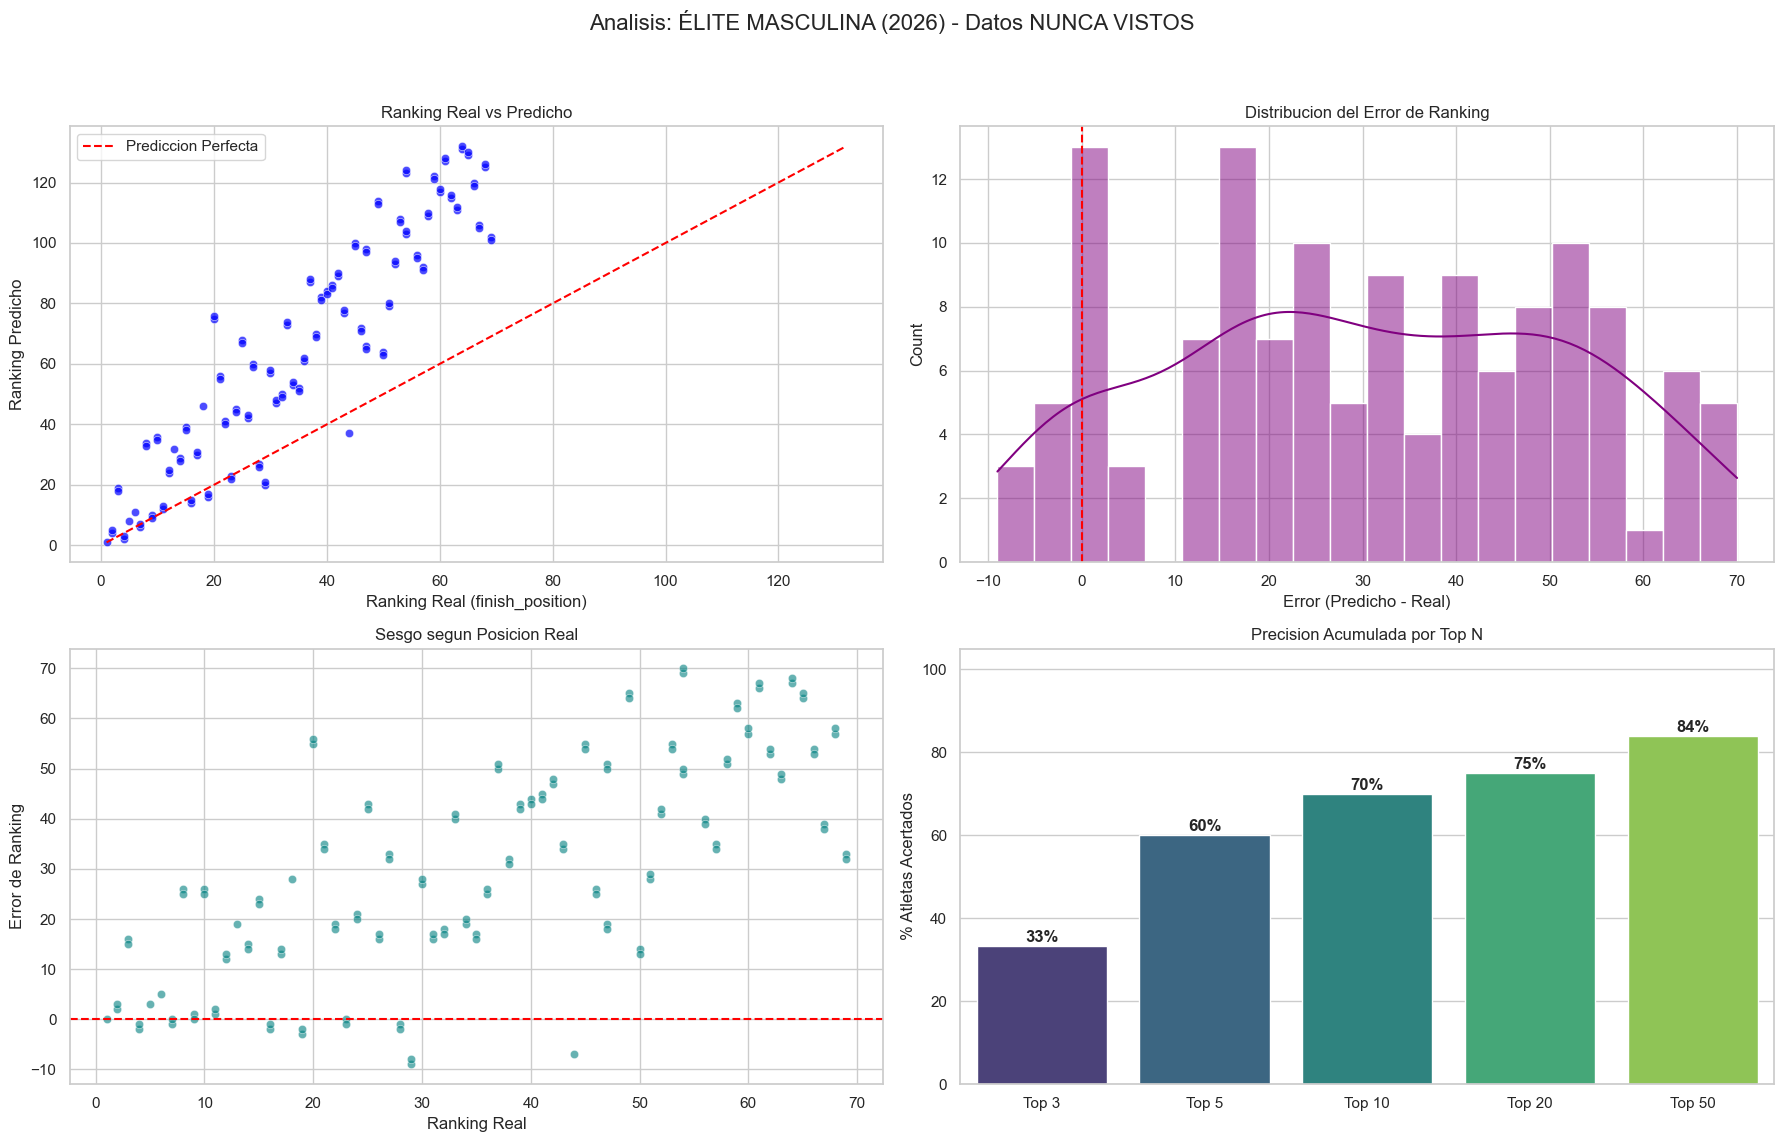

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(f"Analisis: {evento_test} ({season_test}) - Datos NUNCA VISTOS", fontsize=16)

# 1. Scatter Real vs Predicho
sns.scatterplot(x="finish_position", y="RANKING_PREDICHO", data=resultados_finales, alpha=0.7, color="blue", ax=axes[0, 0])
max_rank = max(resultados_finales["finish_position"].max(), resultados_finales["RANKING_PREDICHO"].max())
axes[0, 0].plot([1, max_rank], [1, max_rank], color="red", linestyle="--", label="Prediccion Perfecta")
axes[0, 0].set_title("Ranking Real vs Predicho")
axes[0, 0].set_xlabel("Ranking Real (finish_position)")
axes[0, 0].set_ylabel("Ranking Predicho")
axes[0, 0].legend()

# 2. Distribucion del Error
errores = resultados_finales["RANKING_PREDICHO"] - resultados_finales["finish_position"]
sns.histplot(errores, kde=True, ax=axes[0, 1], color="purple", bins=20)
axes[0, 1].axvline(0, color="red", linestyle="--")
axes[0, 1].set_title("Distribucion del Error de Ranking")
axes[0, 1].set_xlabel("Error (Predicho - Real)")

# 3. Sesgo por Posicion Real
sns.scatterplot(x=resultados_finales["finish_position"], y=errores, ax=axes[1, 0], alpha=0.6, color="teal")
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[1, 0].set_title("Sesgo segun Posicion Real")
axes[1, 0].set_xlabel("Ranking Real")
axes[1, 0].set_ylabel("Error de Ranking")

# 4. Precision Top N
tops = [3, 5, 10, 20, 50]
tops_valid = [t for t in tops if t <= len(resultados_finales)]
aciertos_pct = []
for n in tops_valid:
    real_set = set(resultados_finales.head(n).index)
    pred_set = set(resultados_ordenados.head(n).index)
    aciertos_pct.append(len(real_set.intersection(pred_set)) / n * 100)
sns.barplot(x=[f"Top {n}" for n in tops_valid], y=aciertos_pct, ax=axes[1, 1], palette="viridis")
for i, val in enumerate(aciertos_pct):
    axes[1, 1].text(i, val + 1, f"{val:.0f}%", ha="center", fontweight="bold")
axes[1, 1].set_title("Precision Acumulada por Top N")
axes[1, 1].set_ylabel("% Atletas Acertados")
axes[1, 1].set_ylim(0, 105)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()


### 6. Heatmap: Top 20 Real vs Top 20 Predicho
Un mapa visual para ver exactamente donde coloca el modelo a cada atleta del Top 20 real.

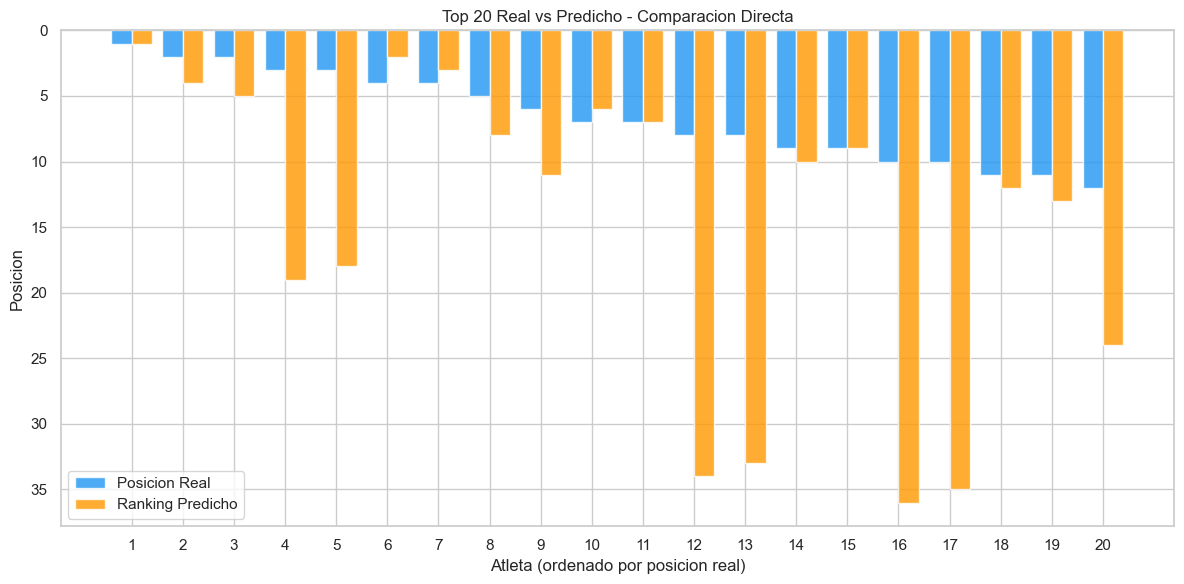

In [7]:
# Crear matriz de confusion de ranking para el Top 20
top_n = min(20, len(resultados_finales))
top_real = resultados_finales.head(top_n).copy()

fig, ax = plt.subplots(figsize=(12, 6))

x = range(top_n)
y_real = top_real["finish_position"].values
y_pred = top_real["RANKING_PREDICHO"].values

ax.bar(x, y_real, width=0.4, align="edge", label="Posicion Real", color="#2196F3", alpha=0.8)
ax.bar([i + 0.4 for i in x], y_pred, width=0.4, align="edge", label="Ranking Predicho", color="#FF9800", alpha=0.8)

ax.set_xlabel("Atleta (ordenado por posicion real)")
ax.set_ylabel("Posicion")
ax.set_title(f"Top {top_n} Real vs Predicho - Comparacion Directa")
ax.set_xticks([i + 0.4 for i in x])
ax.set_xticklabels([f"{i+1}" for i in x])
ax.legend()
ax.invert_yaxis()  # Posicion 1 arriba
plt.tight_layout()
plt.show()


### 7. Curva de Precision Acumulada
Para cada Top N (de 1 a total), que porcentaje de atletas acertamos.

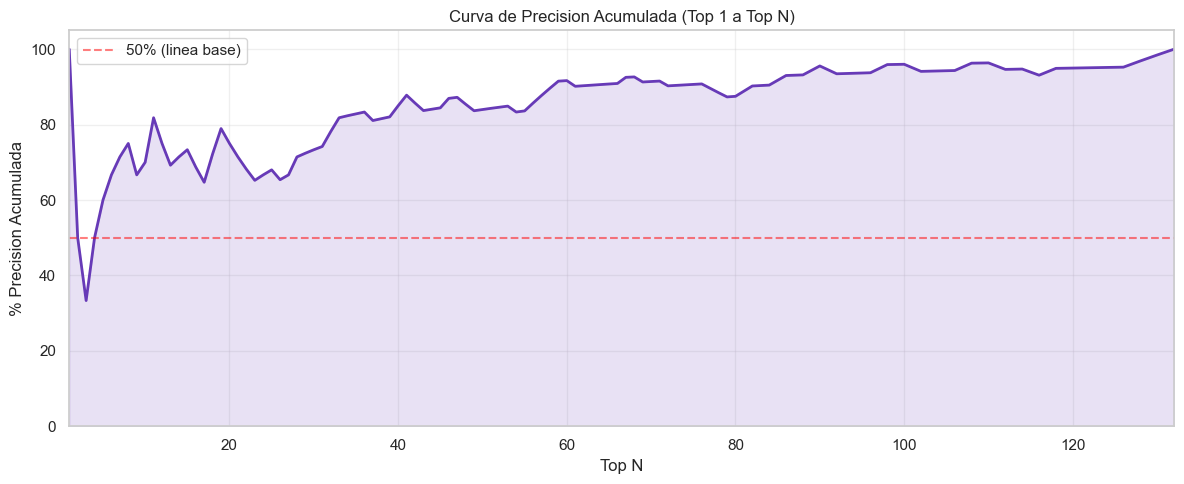

In [8]:
precision_curva = []
total = len(resultados_finales)

for n in range(1, total + 1):
    real_set = set(resultados_finales.head(n).index)
    pred_set = set(resultados_ordenados.head(n).index)
    precision_curva.append(len(real_set.intersection(pred_set)) / n * 100)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(range(1, total + 1), precision_curva, color="#673AB7", linewidth=2)
ax.axhline(y=50, color="red", linestyle="--", alpha=0.5, label="50% (linea base)")
ax.fill_between(range(1, total + 1), precision_curva, alpha=0.15, color="#673AB7")
ax.set_xlabel("Top N")
ax.set_ylabel("% Precision Acumulada")
ax.set_title("Curva de Precision Acumulada (Top 1 a Top N)")
ax.set_xlim(1, total)
ax.set_ylim(0, 105)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 8. Evaluacion Global - TODAS las Carreras de Test
Iteramos por cada carrera de la temporada 2026 y evaluamos el rendimiento carrera a carrera.

In [9]:
resultados_globales = []

for (evento, season), n_part in carreras_test.items():
    df_c = df_test[(df_test["race_event_desc"] == evento) & (df_test["race_season"] == season)].copy()
    if len(df_c) < 10:
        continue
    
    X_c = df_c.drop(columns=[c for c in cols_drop if c in df_c.columns])
    
    try:
        pred = model_azure.predict(X_c)
    except Exception as e:
        print(f"ERROR en {evento}: {e}")
        continue
    
    res = df_c[["finish_position"]].copy()
    res["PREDICCION"] = pred
    res_pred = res.sort_values(by="PREDICCION", ascending=True)
    res_pred["RANKING_PREDICHO"] = range(1, len(res_pred) + 1)
    res_real = res_pred.sort_values(by="finish_position")
    
    mae = mean_absolute_error(res_real["finish_position"], res_real["RANKING_PREDICHO"])
    corr_val, _ = spearmanr(res_real["finish_position"], res_real["RANKING_PREDICHO"])
    
    # Top 3, 5, 10
    top_results = {}
    for tn in [3, 5, 10]:
        if tn <= len(res_real):
            rs = set(res_real.head(tn).index)
            ps = set(res_pred.head(tn).index)
            top_results[f"Top{tn}"] = f"{len(rs.intersection(ps))}/{tn}"
    
    resultados_globales.append({
        "Carrera": evento[:35],
        "N": len(df_c),
        "MAE": round(mae, 2),
        "Spearman": round(corr_val, 3) if not np.isnan(corr_val) else 0,
        **top_results,
    })

df_global = pd.DataFrame(resultados_globales)
display(df_global)

print(f"\n--- RESUMEN GLOBAL (temporada 2026 - NUNCA VISTA) ---")
print(f"MAE promedio:      {df_global['MAE'].mean():.2f} puestos")
print(f"Spearman promedio: {df_global['Spearman'].mean():.3f}")


,Carrera,N,MAE,Spearman,Top3,Top5,Top10
0,ÉLITE MASCULINA,132,31.20,0.93,1/3,3/5,7/10
1,Élite Masculino,113,26.93,0.89,2/3,4/5,9/10
2,Élite Masculina,111,16.90,0.94,0/3,2/5,6/10
3,Elite Masculina,63,5.14,0.93,2/3,4/5,9/10



--- RESUMEN GLOBAL (temporada 2026 - NUNCA VISTA) ---
MAE promedio:      20.04 puestos
Spearman promedio: 0.921


### 9. Comparativa Visual entre Carreras

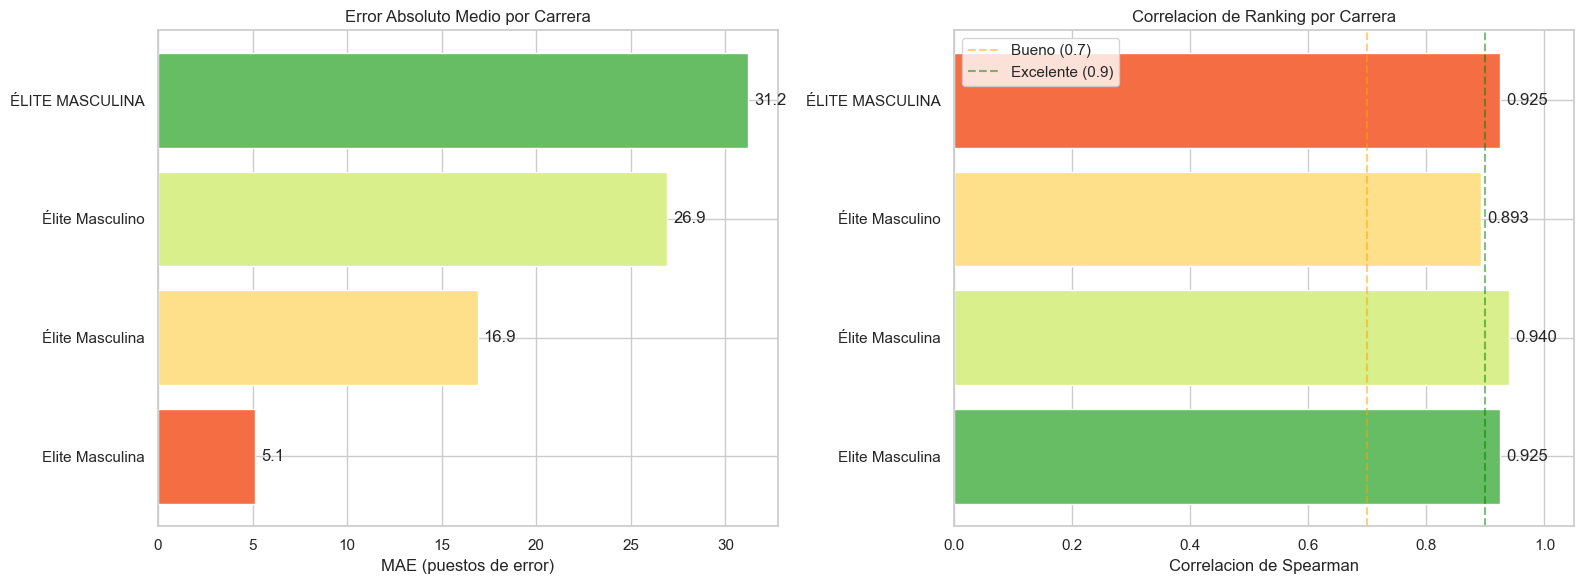

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. MAE por carrera
colors_mae = plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(df_global)))
bars = axes[0].barh(df_global["Carrera"], df_global["MAE"], color=colors_mae)
axes[0].set_xlabel("MAE (puestos de error)")
axes[0].set_title("Error Absoluto Medio por Carrera")
for i, val in enumerate(df_global["MAE"]):
    axes[0].text(val + 0.3, i, f"{val:.1f}", va="center")
axes[0].invert_yaxis()

# 2. Spearman por carrera
colors_sp = plt.cm.RdYlGn(np.linspace(0.2, 0.8, len(df_global)))
axes[1].barh(df_global["Carrera"], df_global["Spearman"], color=colors_sp)
axes[1].set_xlabel("Correlacion de Spearman")
axes[1].set_title("Correlacion de Ranking por Carrera")
axes[1].set_xlim(0, 1.05)
axes[1].axvline(0.7, color="orange", linestyle="--", alpha=0.5, label="Bueno (0.7)")
axes[1].axvline(0.9, color="green", linestyle="--", alpha=0.5, label="Excelente (0.9)")
for i, val in enumerate(df_global["Spearman"]):
    axes[1].text(val + 0.01, i, f"{val:.3f}", va="center")
axes[1].invert_yaxis()
axes[1].legend()

plt.tight_layout()
plt.show()


### 10. Analisis de Residuos por Zona de Ranking
Acierta mejor en los favoritos (Top 10), en el medio del peloton, o en los ultimos?

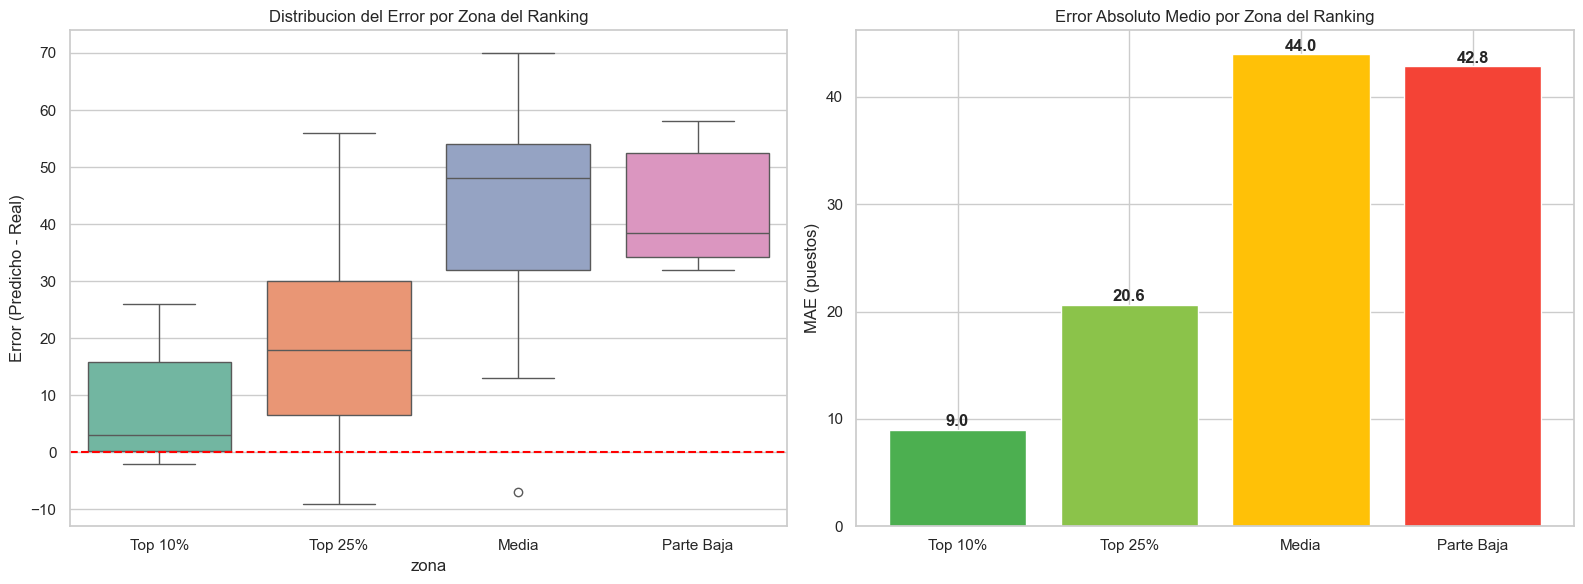


Estadisticas por zona:


,n_atletas,error_medio,mae,error_max
zona,,,,
Top 10%,22,8.64,9.00,26.00
Top 25%,39,19.15,20.64,56.00
Media,65,43.77,43.98,70.00
Parte Baja,6,42.83,42.83,58.00


In [11]:
# Categorizar por zonas del ranking
rf = resultados_finales.copy()
rf["error"] = rf["RANKING_PREDICHO"] - rf["finish_position"]
rf["abs_error"] = rf["error"].abs()

def zona(pos, total):
    pct = pos / total
    if pct <= 0.1:
        return "Top 10%"
    elif pct <= 0.25:
        return "Top 25%"
    elif pct <= 0.5:
        return "Media"
    else:
        return "Parte Baja"

total = len(rf)
rf["zona"] = rf["finish_position"].apply(lambda x: zona(x, total))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Box plot del error por zona
orden_zonas = ["Top 10%", "Top 25%", "Media", "Parte Baja"]
sns.boxplot(data=rf, x="zona", y="error", order=orden_zonas, ax=axes[0], palette="Set2")
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Distribucion del Error por Zona del Ranking")
axes[0].set_ylabel("Error (Predicho - Real)")

# MAE por zona
mae_zona = rf.groupby("zona")["abs_error"].mean().reindex(orden_zonas)
axes[1].bar(mae_zona.index, mae_zona.values, color=["#4CAF50", "#8BC34A", "#FFC107", "#F44336"])
for i, val in enumerate(mae_zona.values):
    axes[1].text(i, val + 0.3, f"{val:.1f}", ha="center", fontweight="bold")
axes[1].set_title("Error Absoluto Medio por Zona del Ranking")
axes[1].set_ylabel("MAE (puestos)")

plt.tight_layout()
plt.show()

print("\nEstadisticas por zona:")
stats = rf.groupby("zona").agg(
    n_atletas=("error", "count"),
    error_medio=("error", "mean"),
    mae=("abs_error", "mean"),
    error_max=("abs_error", "max")
).reindex(orden_zonas).round(2)
display(stats)


### 11. Lineas de Desplazamiento: Posicion Real a Predicha
Cada linea conecta la posicion real del atleta con su posicion predicha. Cuanto mas corta la linea, mejor la prediccion.

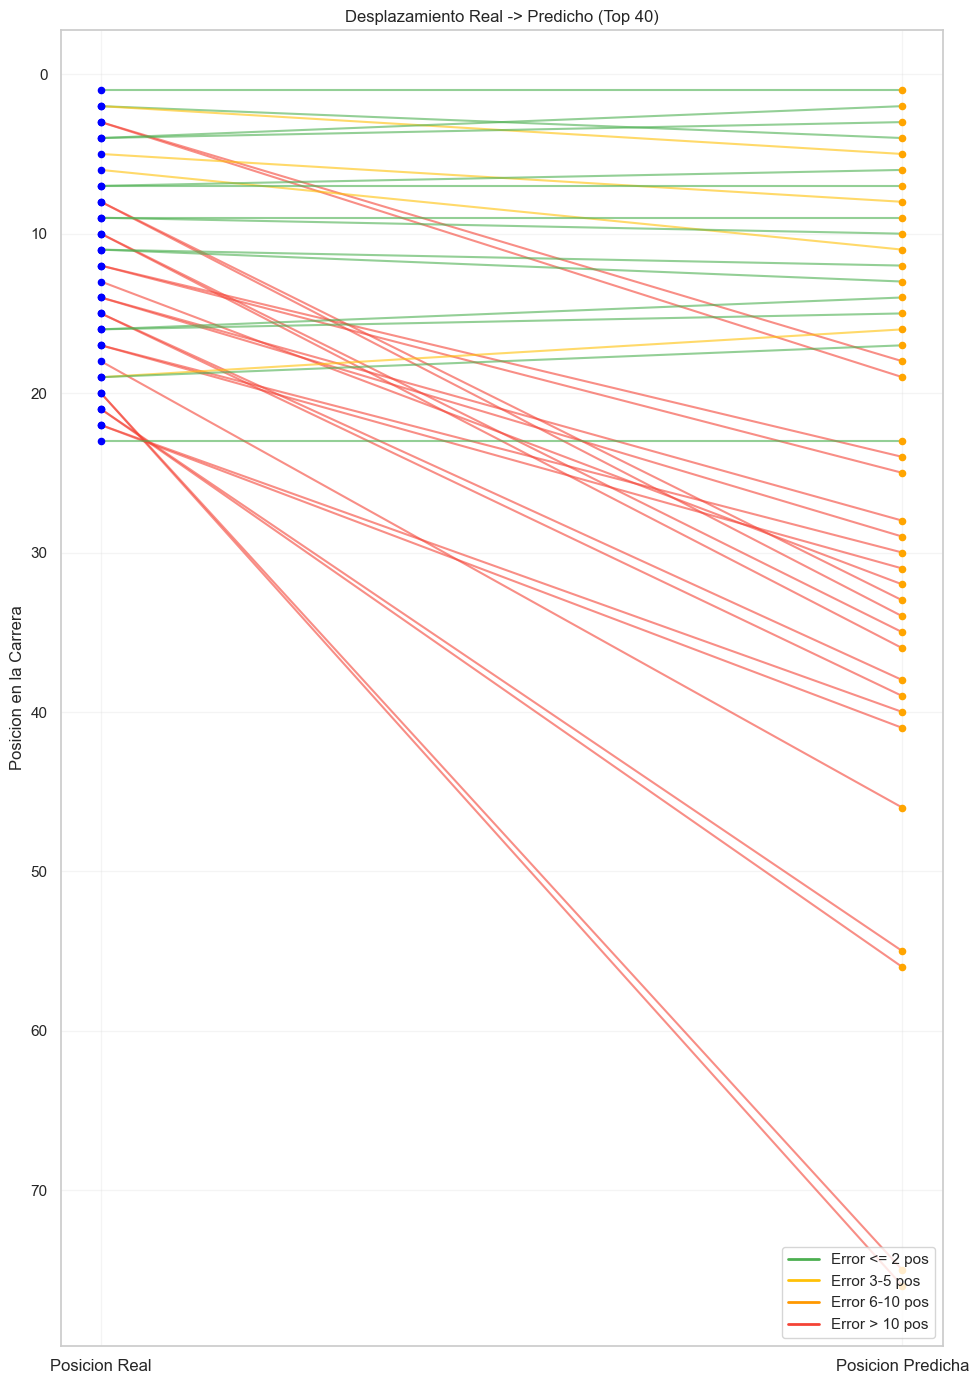

In [12]:
fig, ax = plt.subplots(figsize=(10, 14))

top_show = min(40, len(resultados_finales))
rf_top = resultados_finales.head(top_show).copy()

for _, row in rf_top.iterrows():
    real = row["finish_position"]
    pred = row["RANKING_PREDICHO"]
    error = abs(real - pred)
    
    if error <= 2:
        color = "#4CAF50"  # Verde = muy cerca
    elif error <= 5:
        color = "#FFC107"  # Amarillo = aceptable
    elif error <= 10:
        color = "#FF9800"  # Naranja = regular
    else:
        color = "#F44336"  # Rojo = mal
    
    ax.plot([0, 1], [real, pred], color=color, alpha=0.6, linewidth=1.5)
    ax.scatter(0, real, color="blue", s=20, zorder=5)
    ax.scatter(1, pred, color="orange", s=20, zorder=5)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Posicion Real", "Posicion Predicha"], fontsize=12)
ax.set_ylabel("Posicion en la Carrera")
ax.set_title(f"Desplazamiento Real -> Predicho (Top {top_show})")
ax.invert_yaxis()

# Leyenda manual
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color="#4CAF50", lw=2, label="Error <= 2 pos"),
    Line2D([0], [0], color="#FFC107", lw=2, label="Error 3-5 pos"),
    Line2D([0], [0], color="#FF9800", lw=2, label="Error 6-10 pos"),
    Line2D([0], [0], color="#F44336", lw=2, label="Error > 10 pos"),
]
ax.legend(handles=legend_elements, loc="lower right")
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


### 12. Veredicto Final
Resumen automatizado del rendimiento del modelo.

In [13]:
print("=" * 60)
print("VEREDICTO FINAL DEL MODELO AZURE AUTOML")
print("=" * 60)
print(f"Evaluado sobre: Temporada 2026 (datos NUNCA VISTOS)")
print(f"Carreras evaluadas: {len(df_global)}")
print(f"Total atletas evaluados: {df_global['N'].sum()}")
print()
print(f"Spearman promedio: {df_global['Spearman'].mean():.3f}")
print(f"MAE promedio:      {df_global['MAE'].mean():.2f} puestos")
print()

spearman_avg = df_global["Spearman"].mean()
if spearman_avg >= 0.9:
    print("CALIFICACION: EXCELENTE")
    print("El modelo ordena correctamente a los atletas el 90%+ de las veces.")
    print("Viable para produccion con alta confianza.")
elif spearman_avg >= 0.7:
    print("CALIFICACION: BUENO")
    print("El modelo tiene una correlacion de ranking fuerte.")
    print("Viable para produccion pero con margen de mejora.")
elif spearman_avg >= 0.5:
    print("CALIFICACION: MODERADO")
    print("El modelo capta tendencias pero con errores frecuentes.")
    print("Necesita mejoras antes de produccion.")
else:
    print("CALIFICACION: INSUFICIENTE")
    print("El modelo no tiene capacidad predictiva real.")
    print("Se necesitan mas datos o mejores features.")


VEREDICTO FINAL DEL MODELO AZURE AUTOML
Evaluado sobre: Temporada 2026 (datos NUNCA VISTOS)
Carreras evaluadas: 4
Total atletas evaluados: 419

Spearman promedio: 0.921
MAE promedio:      20.04 puestos

CALIFICACION: EXCELENTE
El modelo ordena correctamente a los atletas el 90%+ de las veces.
Viable para produccion con alta confianza.
